In [1]:
# 06 - Transfer learning (TP8): ResNet50 and VGG16, pre-trained on ImageNet, on our heart sounds
# (project model 4: "CNN pré-entraîné ResNet18/50", and VGG16 to compare, like the prof's TP)
#
# Transfer learning = we re-use a CNN that already learned to "see" on ImageNet (1 million photos, 1000 classes).
# The course gives 4 ways to use a pre-trained model:
#   1. Classifier: use it as it is -> its 1000 ImageNet classes have no heart sounds, useless for us
#   2. Standalone feature extractor: it turns each image into a list of numbers (the features),
#      then a NEW small model learns on these numbers                                   <- what we do
#   3. Integrated feature extractor: the same thing inside one model, the pre-trained layers frozen
#   4. Weight initialization (fine-tuning): all the layers learn again, with a tiny learning rate
# Why 2: on Windows TensorFlow has no GPU, so training ResNet50 itself (3 or 4) would take hours on our CPU
# (the prof's TP runs on Google Colab with a GPU). With 2, the slow part (ResNet50, VGG16) runs only ONCE per wav.
#
# 1. our Mel spectrograms (made in TP7) -> colour images of 224 x 224 x 3, like the prof's spectrogram images
# 2. ResNet50 and VGG16 (include_top=False) turn each image into a list of numbers
# 3. the fixed TEST set of notebook 01 (20% of the wavs) is put aside: never used to train or to choose a setting
# 4. VALIDATION: a small new classifier learns on these numbers, on the 3 folds of the 80% train part
# 5. TEST: the final classifier learns on the whole 80% part, then is tested ONCE on the 20% test set
# 6. MLflow (experiment audio_benchmark_final): one run per pre-trained model, with its final model
#    (pre-trained part + our classifier), and inside it 1 small run per fold, with its training and validation curves

In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"    # hide the TensorFlow info messages

import json
import time
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import IPython.display as ipd

from sklearn.model_selection import KFold, train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import roc_curve, auc                 # the ROC curve and the area under it (AUC)

import tensorflow as tf
import keras
from keras.models import Sequential
from keras.layers import Input, Dense, Dropout, BatchNormalization
from keras.optimizers import Adam

# the pre-trained models (like in the prof's TP), and how each one wants its images prepared
from keras.applications.resnet50 import ResNet50, preprocess_input as resnet_preprocess
from keras.applications.vgg16 import VGG16, preprocess_input as vgg_preprocess

import mlflow
import mlflow.keras

tf.get_logger().setLevel("ERROR")    # hide the "retracing" warnings of TensorFlow

In [3]:
# my folders (the same as in the other notebooks)
project_folder = "D:/MLOps_Project/"
plots_folder = "D:/MLOps_Project/models plots/"    # the figures of the notebooks (saved here, then sent to MLflow)


def load_data(file_name):
    with open(file_name, "rb") as f:
        return pickle.load(f)


def save_data(data, file_name):
    with open(file_name, "wb") as f:
        pickle.dump(data, f)

In [4]:
# ==================== Merge: Farah vs Zaineb (the result of notebook 09, part 2) ====================
# For the transfer learning (ResNet50) we tried Farah's classifier (BatchNorm + Dense 128 + Dropout 0.5, 30 epochs)
# and merged versions with Zaineb's ideas (early stopping on 10% of the training fold, a bigger Dense 256), with the
# SAME protocol: the same 3681 clean wavs, the same 80% train part, the same 3 validation folds, the same metrics
# (the 20% test set is never used to choose). (Zaineb's own ResNet50 - grey image 128 x 128 - had already lost in part 1.)
# Rule: a candidate replaces the current version if it has a higher validation recall (if it loses more than 0.01 of
# F1 it is a trade-off and we keep the higher recall, the PDF rule), or a higher F1 without losing more than 0.01 of
# recall. Accuracy alone is misleading here: a model that says "normal" more often gets a higher accuracy (78% of the
# wavs are normal) but misses more sick hearts.
# -> the winner = MERGED: Farah's classifier with Dense 256 + early stopping (a bit more recall, the same F1).
#    The same method is used for VGG16 (kept in MLflow to compare).
with open(plots_folder + "merge_results.json") as f:
    merge = json.load(f)["ResNet50"]
ipd.display(pd.DataFrame(merge["candidates"])[["name", "from", "recall", "f1", "precision", "accuracy", "kept"]])
print("Kept:", merge["winner"])
assert merge["winner"] == "early_stopping_256", "the winner changed: update this notebook"

,name,from,recall,f1,precision,accuracy,kept
0,"Farah: BN + Dense 128 + Dropout, 30 epochs",Farah,0.789,0.748,0.713,0.881,False
1,"merged: Dense 128 + early stopping [29, 35, 29]",merged,0.780,0.729,0.687,0.870,False
2,"merged: Dense 256 + early stopping [23, 24, 29]",merged,0.793,0.746,0.704,0.879,True


Kept: early_stopping_256


In [5]:
# the Mel spectrograms made by the CNN notebook (04): the same clean wavs, 5 s, 2000 Hz, 40 bands x 157 moments
spectrograms = load_data(project_folder + "cnn_spectrograms.data")
labels = load_data(project_folder + "cnn_labels.data")
files = np.array(load_data(project_folder + "cnn_files.data"))    # the name of the wav of each row

X = np.array(spectrograms)    # (number of wavs, 40, 157), in dB (from -80 to 0)
y = np.array(labels)          # 1 = abnormal, 0 = normal
print("X:", X.shape, "| normal:", np.sum(y == 0), "| abnormal:", np.sum(y == 1))

X: (3681, 40, 157) | normal: 2855 | abnormal: 826


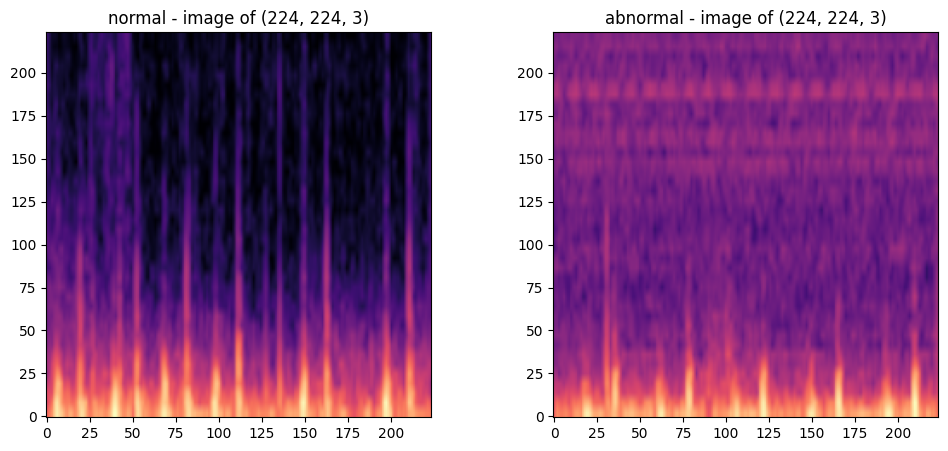

In [6]:
# ==================== 1. From a spectrogram to an "ImageNet" image ====================
# The ImageNet models learned on colour photos: 224 x 224 pixels, 3 colours (red, green, blue) from 0 to 255.
# Like the prof's images: his spectrograms are drawn by librosa (specshow) with the "magma" colours.
# (his images are 480 x 640: 6 times more pixels than 224 x 224 -> 6 times slower on our CPU)
#
# plt.cm.magma() gives a colour to each number from 0 to 1 (0 = black, 0.5 = pink, 1 = light yellow),
# as 4 numbers (red, green, blue, transparency): [..., :3] keeps red, green, blue
def make_images(S):
    images = plt.cm.magma((S + 80) / 80)[..., :3] * 255    # dB (-80 to 0) -> 0 to 1 -> colours from 0 to 255
    images = tf.image.resize(images, (224, 224)).numpy()   # (n, 40, 157, 3) -> (n, 224, 224, 3): stretched
    return images


# what the pre-trained models will see: 1 normal and 1 abnormal wav
examples = make_images(np.array([X[y == 0][0], X[y == 1][0]]))
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(examples[0] / 255, origin="lower")    # / 255: imshow wants the colours from 0 to 1
plt.title("normal - image of " + str(examples[0].shape))
plt.subplot(1, 2, 2)
plt.imshow(examples[1] / 255, origin="lower")
plt.title("abnormal - image of " + str(examples[1].shape))
plt.show()

In [7]:
# ==================== 2. The pre-trained models turn each image into numbers (the features) ====================
# like the prof's TP: a list of models and their names (we could add more: VGG19, MobileNet, InceptionV3, ...)
all_deep_models = [ResNet50, VGG16]
all_model_name_txt = ["ResNet50", "VGG16"]
all_preprocess = [resnet_preprocess, vgg_preprocess]    # each model wants its images prepared like on ImageNet

base_models = {}    # the pre-trained part of each model (we need it again at the end, for the final model)
features = {}       # the numbers of each wav, for each model


def extract_features(base_model, preprocess):
    # 32 images at a time (all the images at once would need ~2 GB of memory)
    all_features = []
    for start in range(0, len(X), 32):
        images = preprocess(make_images(X[start:start + 32]))
        all_features.append(base_model.predict(images, verbose=0))
    return np.concatenate(all_features)


for i in range(len(all_deep_models)):
    model_name_txt = all_model_name_txt[i]
    # weights="imagenet": the weights learned on ImageNet (downloaded the first time: ~95 MB for ResNet50,
    #                     ~60 MB for VGG16, then kept in .keras/models/ like the course says)
    # include_top=False: WITHOUT the last layers (its 1000 ImageNet classes), like in the course
    # pooling="avg": a GlobalAveragePooling2D at the end (like the prof): 1 number per feature map
    base_model = all_deep_models[i](weights="imagenet", include_top=False, pooling="avg", input_shape=(224, 224, 3))
    base_model.trainable = False    # frozen: its ImageNet weights never change
    base_models[model_name_txt] = base_model

    # the slow part (a few minutes): done once, then saved like the other features of the project
    # (to make them again, delete the .data file)
    file_name = project_folder + "tl_features_" + model_name_txt + ".data"
    if os.path.exists(file_name):
        features[model_name_txt] = np.array(load_data(file_name))
    else:
        start_time = time.time()
        features[model_name_txt] = extract_features(base_model, all_preprocess[i])
        save_data(features[model_name_txt], file_name)
        print(model_name_txt, ": features made in", round(time.time() - start_time), "s")
    assert len(features[model_name_txt]) == len(y), "the features do not match the spectrograms: delete " + file_name
    print(model_name_txt, ":", len(base_model.layers), "layers,", base_model.count_params(), "weights (all frozen)",
          "-> each wav = a list of", features[model_name_txt].shape[1], "numbers")

ResNet50 : 176 layers, 23587712 weights (all frozen) -> each wav = a list of 2048 numbers


VGG16 : 20 layers, 14714688 weights (all frozen) -> each wav = a list of 512 numbers


In [8]:
# ==================== 3. The fixed TEST set (made by notebook 01): put aside, never used to train ====================
# - 80% = the TRAIN part: the 3 folds (validation) and the training of the final classifier happen only here
# - 20% = the TEST part: used ONCE at the end, to test the final model
# (the features of ALL the wavs were made before: no problem, the pre-trained part never learns from our wavs)
with open(project_folder + "splits/test_files.json") as f:
    split = json.load(f)
test_label = dict(zip(split["test_files"], split["test_labels"]))    # name of a test wav -> its class

assert len(files) == len(y), "cnn_files.data does not match: run notebook 04 again"
is_test = np.array([name in test_label for name in files])          # True for the 20% test wavs
assert is_test.sum() == split["n_test"], "some test wavs are missing: run notebook 01 again"
for i in np.where(is_test)[0]:
    assert y[i] == test_label[files[i]], "the class of " + files[i] + " is not the same in notebook 01"

y_train, y_test = y[~is_test], y[is_test]    # ~ = "not": the 80% train part
print("train (80%):", len(y_train), "wavs | test (20%):", len(y_test), "wavs")

train (80%): 2944 wavs | test (20%): 737 wavs


In [9]:
# ==================== 4. Our new small classifier: it learns on the features ====================
# like the end of the prof's model (BatchNormalization, Dense, Dropout, 1 neuron with sigmoid), but smaller:
# we have only ~1960 train wavs per fold, a big classifier (Dense 1024 + 512 + 128) would learn them by heart.
# Merge: Dense 256 (Zaineb's size) instead of 128, and early stopping (see the training cell)
def build_head(n_features):
    model = Sequential()
    model.add(Input(shape=(n_features,)))        # the features of 1 wav (2048 numbers for ResNet50, 512 for VGG16)
    model.add(BatchNormalization())               # puts the features on the same scale (like StandardScaler in TP3)
    model.add(Dense(256, activation="relu"))      # 256 neurons combine the features
    model.add(Dropout(0.5))                       # switches off 50% of the neurons while training -> less overfitting
    model.add(Dense(1, activation="sigmoid"))     # 1 neuron: the probability that the heart is abnormal

    # Adam with learning_rate=0.0001 (10 x smaller than TP7): the features are already good, so with 0.001
    # the classifier learns the train wavs by heart in a few epochs (overfitting: the validation loss goes up).
    # Only this NEW small model learns.
    # (the prof's 0.000001 is for fine-tuning: tiny changes to the pre-trained layers themselves)
    model.compile(optimizer=Adam(learning_rate=0.0001), loss="binary_crossentropy", metrics=["accuracy"])
    return model


build_head(2048).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ batch_normalization             │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 532,993 (2.03 MB)

 Trainable params: 528,897 (2.02 MB)

 Non-trainable params: 4,096 (16.00 KB)

In [10]:
# ==================== The plots of the notebook ====================
def PlotConfusionMatrix(cm, title):
    # cm[i][j] = number of wavs of class i (true) that the model put in class j (predicted)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", cbar=False,
                xticklabels=["normal", "abnormal"], yticklabels=["normal", "abnormal"])
    plt.title(title)
    plt.xlabel("Predicted class")
    plt.ylabel("True class")


def plot_roc(y_true, y_score, title):
    # ROC curve: for every threshold, the % of sick hearts found (true positive rate = recall) against the % of
    # normal hearts called abnormal (false positive rate). AUC = the area under it (1 = perfect, 0.5 = random)
    false_positive_rate, true_positive_rate, thresholds = roc_curve(y_true, y_score)
    area = auc(false_positive_rate, true_positive_rate)
    plt.plot(false_positive_rate, true_positive_rate, label="AUC = {:.3f}".format(area))
    plt.plot([0, 1], [0, 1], "--", color="grey", label="random")
    plt.title(title)
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate (recall)")
    plt.legend(loc="lower right")
    return area


# like plot_acc_loss() of the prof: accuracy and loss after each epoch, train vs the early-stopping part (10% of the
# training fold, it decides when to stop) + the confusion matrix and the ROC curve of the VALIDATION third of the fold
def plot_fold(history, y_true, y_prob, model_name_txt, fold):
    title = model_name_txt + " - Fold " + str(fold)
    plt.figure(figsize=(22, 4.5))
    plt.subplot(1, 4, 1)
    plt.plot(history.history["accuracy"], label="train")
    plt.plot(history.history["val_accuracy"], label="early-stopping part")
    plt.title(title + " - accuracy")
    plt.xlabel("epoch")
    plt.legend()
    plt.subplot(1, 4, 2)
    plt.plot(history.history["loss"], label="train")
    plt.plot(history.history["val_loss"], label="early-stopping part")
    plt.title(title + " - loss")
    plt.xlabel("epoch")
    plt.legend()
    plt.subplot(1, 4, 3)
    PlotConfusionMatrix(confusion_matrix(y_true, (y_prob > 0.5).astype(int)), title + " - validation")
    plt.subplot(1, 4, 4)
    plot_roc(y_true, y_prob, title + " - ROC (validation)")
    plt.tight_layout()
    plt.savefig(plots_folder + "tp8_" + model_name_txt + "_val_fold" + str(fold) + ".png")
    plt.show()

==================== ResNet50 - Fold 1


stopped after 23 epochs


              precision    recall  f1-score   support

      normal       0.93      0.91      0.92       756
    abnormal       0.71      0.77      0.74       226

    accuracy                           0.87       982
   macro avg       0.82      0.84      0.83       982
weighted avg       0.88      0.87      0.88       982



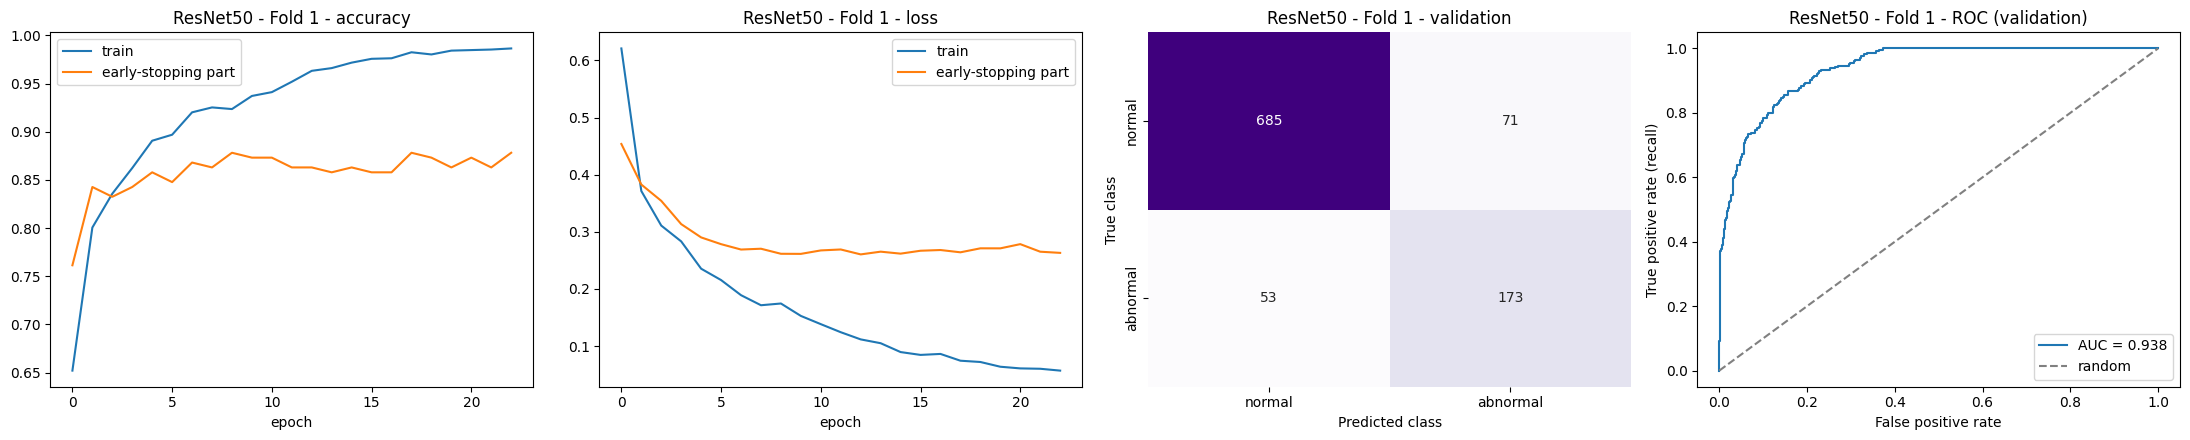

==================== ResNet50 - Fold 2


stopped after 24 epochs


              precision    recall  f1-score   support

      normal       0.95      0.91      0.93       759
    abnormal       0.74      0.83      0.78       222

    accuracy                           0.90       981
   macro avg       0.84      0.87      0.86       981
weighted avg       0.90      0.90      0.90       981



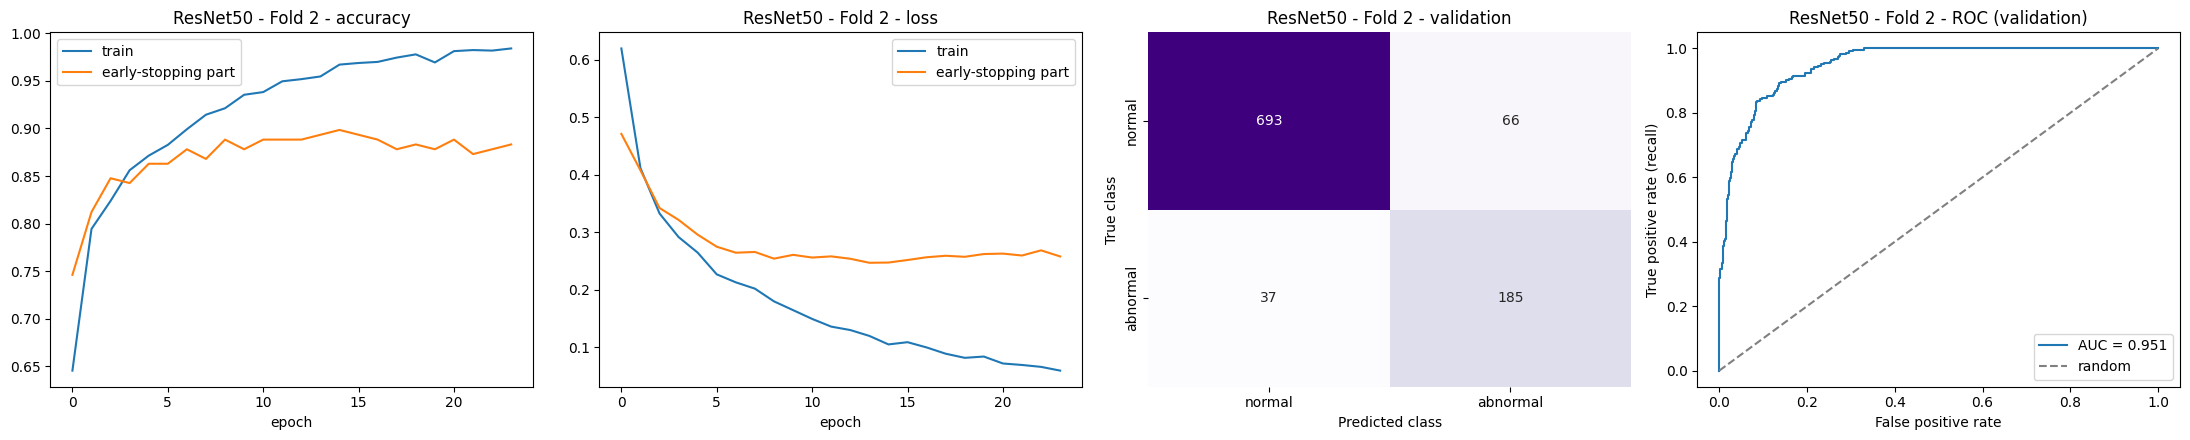

==================== ResNet50 - Fold 3


stopped after 29 epochs


              precision    recall  f1-score   support

      normal       0.94      0.89      0.91       768
    abnormal       0.67      0.78      0.72       213

    accuracy                           0.87       981
   macro avg       0.80      0.84      0.82       981
weighted avg       0.88      0.87      0.87       981



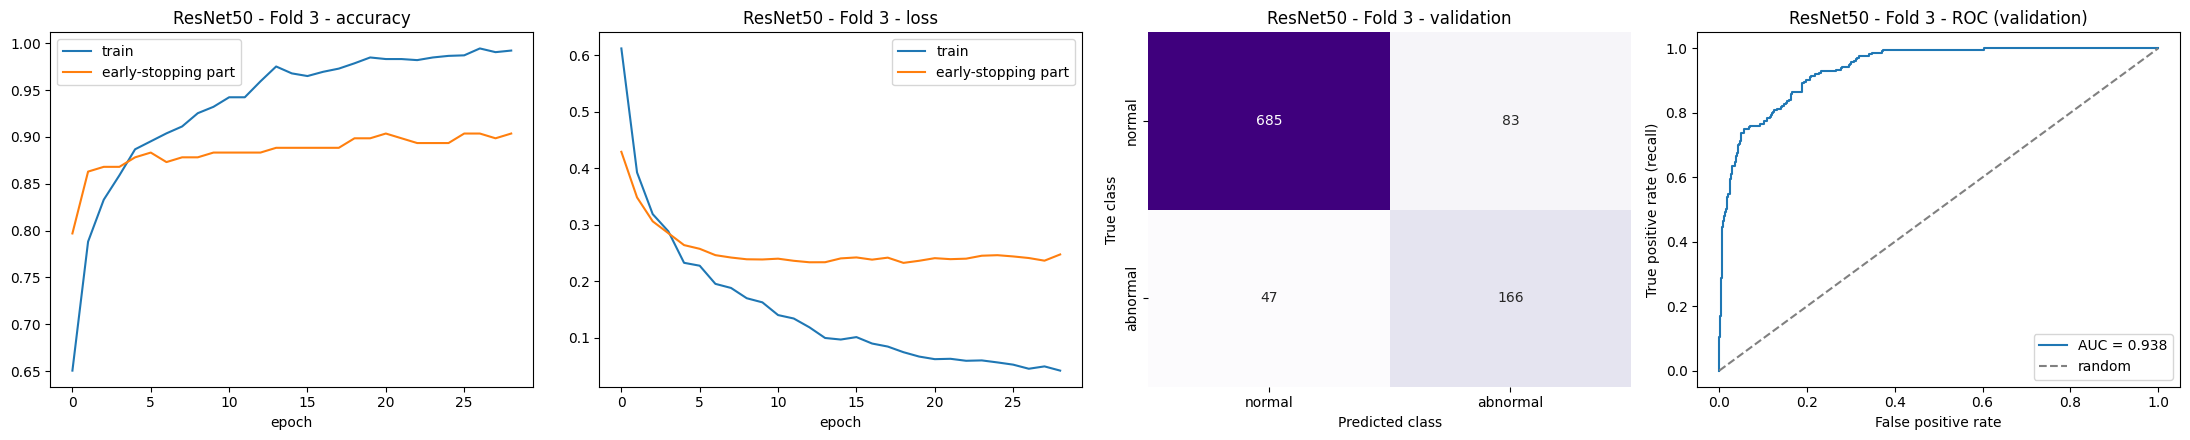

==================== VGG16 - Fold 1


stopped after 49 epochs


              precision    recall  f1-score   support

      normal       0.94      0.88      0.91       756
    abnormal       0.67      0.80      0.73       226

    accuracy                           0.86       982
   macro avg       0.80      0.84      0.82       982
weighted avg       0.88      0.86      0.87       982



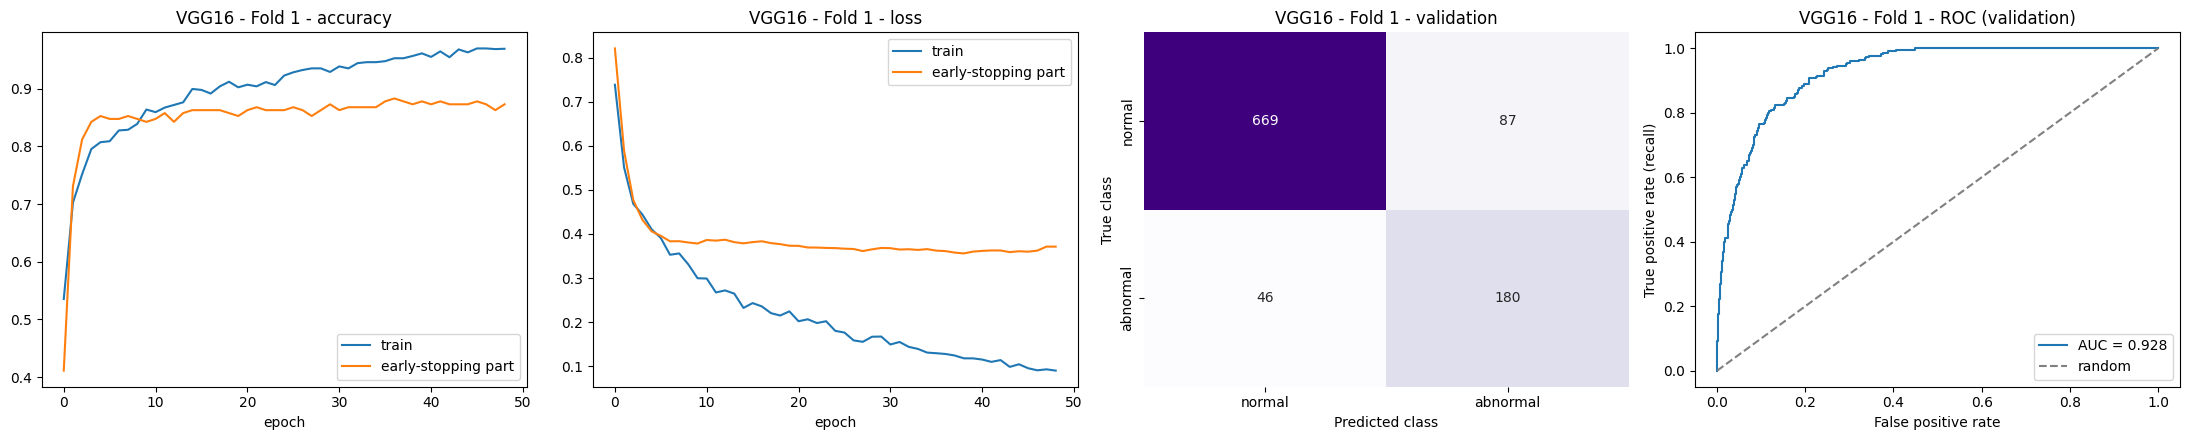

==================== VGG16 - Fold 2


stopped after 56 epochs


              precision    recall  f1-score   support

      normal       0.92      0.90      0.91       759
    abnormal       0.69      0.75      0.72       222

    accuracy                           0.87       981
   macro avg       0.81      0.82      0.81       981
weighted avg       0.87      0.87      0.87       981



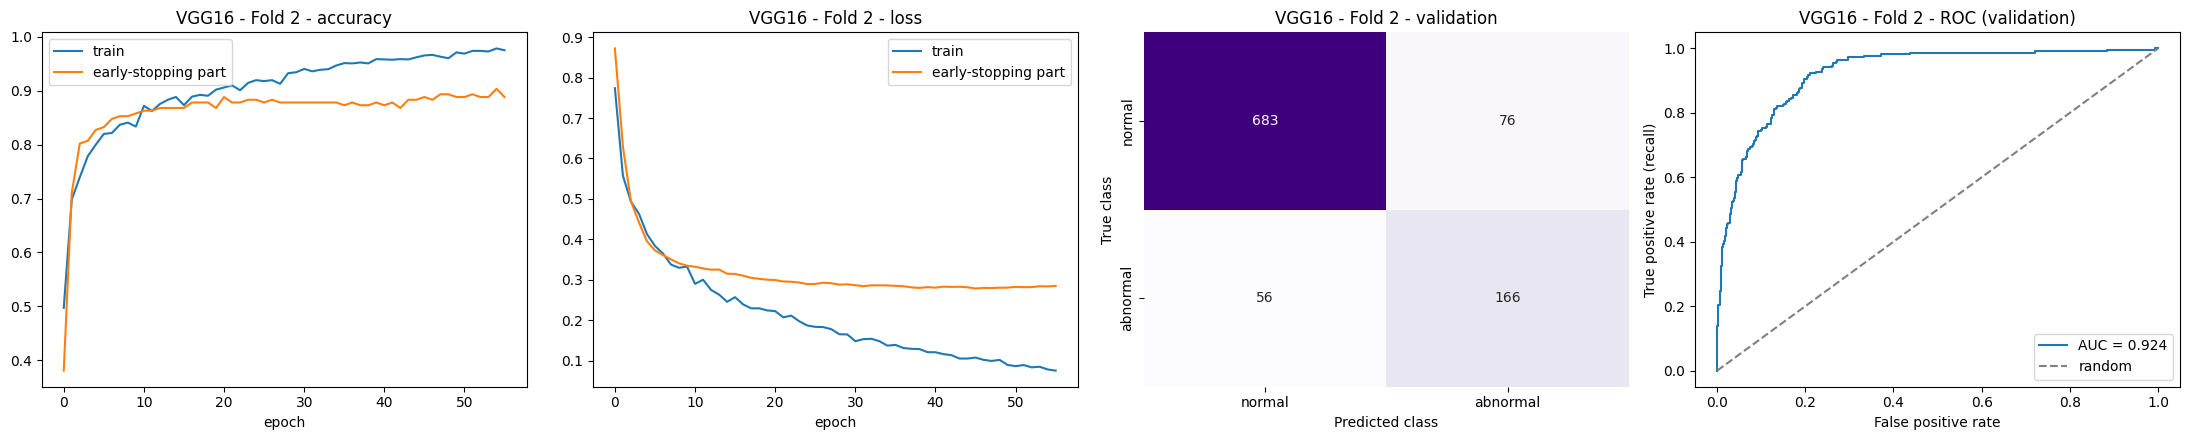

==================== VGG16 - Fold 3


stopped after 41 epochs


              precision    recall  f1-score   support

      normal       0.94      0.88      0.91       768
    abnormal       0.65      0.81      0.72       213

    accuracy                           0.86       981
   macro avg       0.79      0.84      0.81       981
weighted avg       0.88      0.86      0.87       981



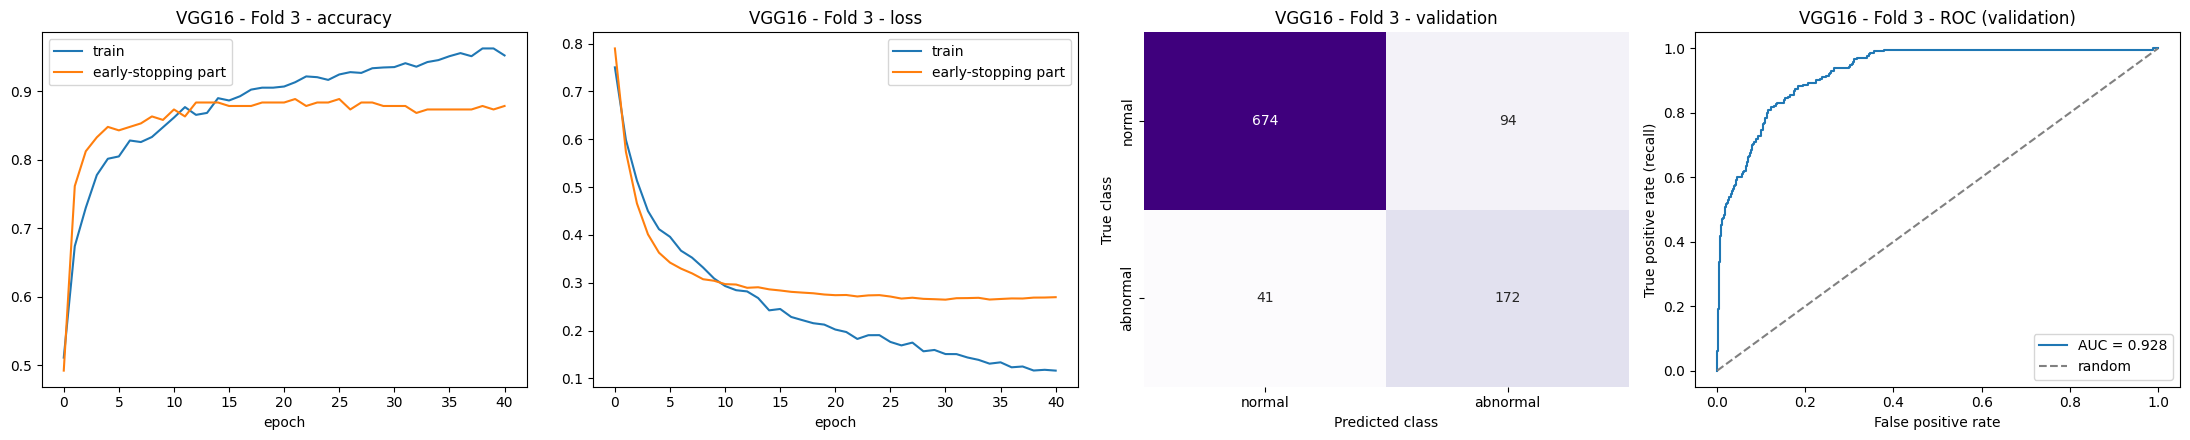

In [11]:
# ==================== 5. VALIDATION: 3 folds on the 80% train part (the same folds as all the other models) ====================
MAX_EPOCHS = 60     # at most 60 passes over the train wavs (it's fast: the classifier is small)
BATCH_SIZE = 32     # the weights change after every 32 wavs
# like TP7: each abnormal wav counts 3.5x more (computed on the train part only)
class_weight = {0: len(y_train) / (2 * np.sum(y_train == 0)), 1: len(y_train) / (2 * np.sum(y_train == 1))}


def train_head(F, y, train_index):
    # Zaineb's early stopping: 10% of the training wavs are kept aside ("stop" part, never the validation third);
    # the training stops when the loss on this part has not improved for 10 epochs, and the best weights come back
    fit_index, stop_index = train_test_split(train_index, test_size=0.1, stratify=y[train_index], random_state=0)
    keras.utils.set_random_seed(0)    # the same random start each time -> the same results if we run it again
    head = build_head(F.shape[1])
    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    history = head.fit(F[fit_index], y[fit_index], epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
                       class_weight=class_weight, validation_data=(F[stop_index], y[stop_index]),
                       callbacks=[early_stop], verbose=0)
    return head, history


kfold = KFold(n_splits=3, shuffle=True, random_state=1)    # the same 3 folds as TP3, TP4 and TP7
results = []          # 1 line per (model, fold)
all_histories = {}    # the 3 Keras histories (curves) of each model, kept for MLflow
oof = {}              # the "out-of-fold" probabilities of each model (for notebook 08)
for model_name_txt in all_model_name_txt:
    F_train = features[model_name_txt][~is_test]
    histories = []
    oof_prob = np.zeros(len(y_train))
    oof_fold = np.zeros(len(y_train), dtype=int)
    fold = 1
    for train_index, val_index in kfold.split(F_train):
        print("====================", model_name_txt, "- Fold", fold)
        head, history = train_head(F_train, y_train, train_index)
        histories.append(history)
        print("stopped after", len(history.history["loss"]), "epochs")

        # the sigmoid gives a probability: more than 0.5 -> abnormal (1), else normal (0)
        y_val = y_train[val_index]
        y_prob = head.predict(F_train[val_index], verbose=0).ravel()
        y_pred = (y_prob > 0.5).astype(int)
        oof_prob[val_index] = y_prob
        oof_fold[val_index] = fold
        false_positive_rate, true_positive_rate, thresholds = roc_curve(y_val, y_prob)
        print(classification_report(y_val, y_pred, target_names=["normal", "abnormal"]))
        results.append({
            "model": model_name_txt,
            "fold": fold,
            "accuracy": accuracy_score(y_val, y_pred),
            "precision": precision_score(y_val, y_pred),    # precision, recall, f1: of the abnormal class
            "recall": recall_score(y_val, y_pred),
            "f1": f1_score(y_val, y_pred),
            "auc": auc(false_positive_rate, true_positive_rate),
            "y_val": y_val,                                 # kept for the summary figure
            "y_prob": y_prob,
        })
        plot_fold(history, y_val, y_prob, model_name_txt, fold)
        fold = fold + 1
    all_histories[model_name_txt] = histories
    oof[model_name_txt] = (oof_prob, oof_fold)

      model  fold  accuracy  precision  recall     f1    auc
0  ResNet50     1     0.874      0.709   0.765  0.736  0.938
1  ResNet50     2     0.895      0.737   0.833  0.782  0.951
2  ResNet50     3     0.867      0.667   0.779  0.719  0.938
3     VGG16     1     0.865      0.674   0.796  0.730  0.928
4     VGG16     2     0.865      0.686   0.748  0.716  0.924
5     VGG16     3     0.862      0.647   0.808  0.718  0.928

Mean of the 3 folds (validation):
          accuracy  precision  recall     f1    auc
model                                              
ResNet50     0.879      0.704   0.793  0.746  0.942
VGG16        0.864      0.669   0.784  0.721  0.927


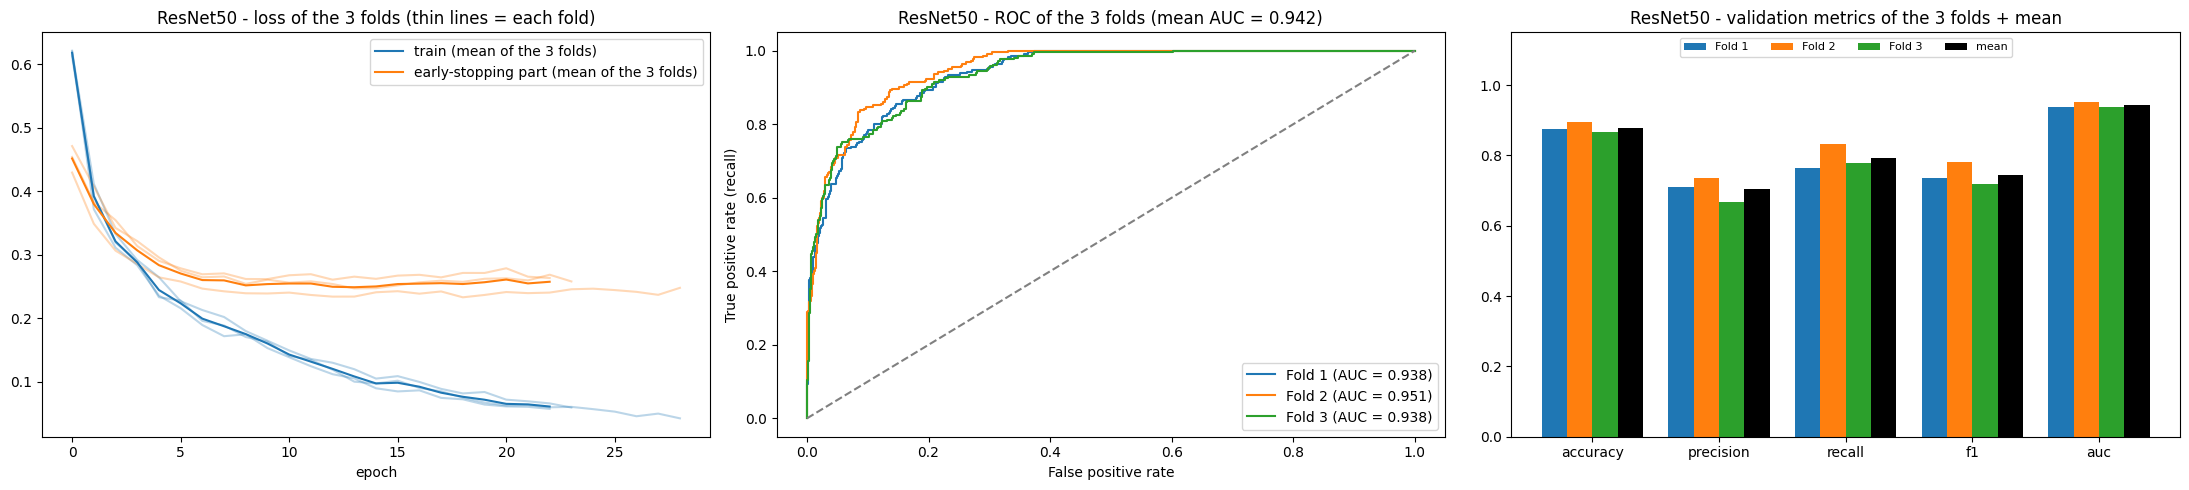

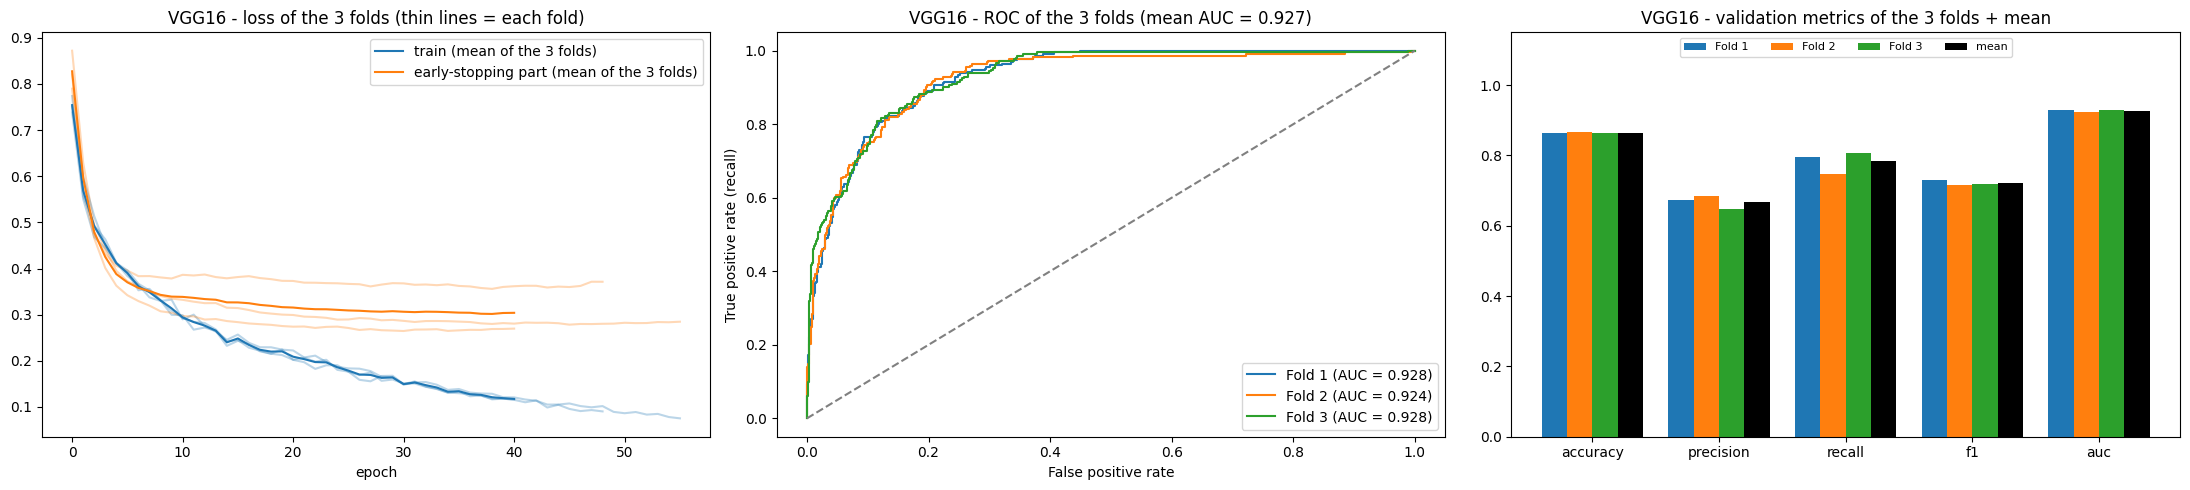

In [12]:
metrics = ["accuracy", "precision", "recall", "f1", "auc"]
table = pd.DataFrame(results)[["model", "fold"] + metrics]
print(table.round(3))
print()
print("Mean of the 3 folds (validation):")
print(table.groupby("model")[metrics].mean().round(3))

# ONE summary figure per model: the loss curves of the 3 folds, their ROC curves, their metrics + the mean
for model_name_txt in all_model_name_txt:
    histories = all_histories[model_name_txt]
    model_results = [r for r in results if r["model"] == model_name_txt]
    model_table = table[table["model"] == model_name_txt].reset_index(drop=True)
    plt.figure(figsize=(22, 5))

    plt.subplot(1, 3, 1)
    for h in histories:    # thin lines: each fold (each fold stops at a different epoch)
        plt.plot(h.history["loss"], color="tab:blue", alpha=0.3)
        plt.plot(h.history["val_loss"], color="tab:orange", alpha=0.3)
    n = min([len(h.history["loss"]) for h in histories])    # the mean on the epochs that all the folds have
    plt.plot(np.mean([h.history["loss"][:n] for h in histories], axis=0), color="tab:blue",
             label="train (mean of the 3 folds)")
    plt.plot(np.mean([h.history["val_loss"][:n] for h in histories], axis=0), color="tab:orange",
             label="early-stopping part (mean of the 3 folds)")
    plt.title(model_name_txt + " - loss of the 3 folds (thin lines = each fold)")
    plt.xlabel("epoch")
    plt.legend()

    plt.subplot(1, 3, 2)
    for r in model_results:
        false_positive_rate, true_positive_rate, thresholds = roc_curve(r["y_val"], r["y_prob"])
        plt.plot(false_positive_rate, true_positive_rate,
                 label="Fold " + str(r["fold"]) + " (AUC = {:.3f})".format(r["auc"]))
    plt.plot([0, 1], [0, 1], "--", color="grey")
    plt.title(model_name_txt + " - ROC of the 3 folds (mean AUC = {:.3f})".format(model_table["auc"].mean()))
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate (recall)")
    plt.legend(loc="lower right")

    plt.subplot(1, 3, 3)
    x = np.arange(len(metrics))
    for i in range(3):
        plt.bar(x - 0.3 + 0.2 * i, model_table.loc[i, metrics], width=0.2, label="Fold " + str(i + 1))
    plt.bar(x + 0.3, model_table[metrics].mean(), width=0.2, color="black", label="mean")
    plt.xticks(x, metrics)
    plt.ylim(0, 1.15)
    plt.title(model_name_txt + " - validation metrics of the 3 folds + mean")
    plt.legend(loc="upper center", ncol=4, fontsize=8)

    plt.tight_layout()
    plt.savefig(plots_folder + "tp8_" + model_name_txt + "_val_summary.png")
    plt.show()

ResNet50 : final classifier stopped after 29 epochs


==================== ResNet50 - test set
              precision    recall  f1-score   support

      normal       0.94      0.91      0.93       572
    abnormal       0.72      0.81      0.76       165

    accuracy                           0.89       737
   macro avg       0.83      0.86      0.84       737
weighted avg       0.89      0.89      0.89       737



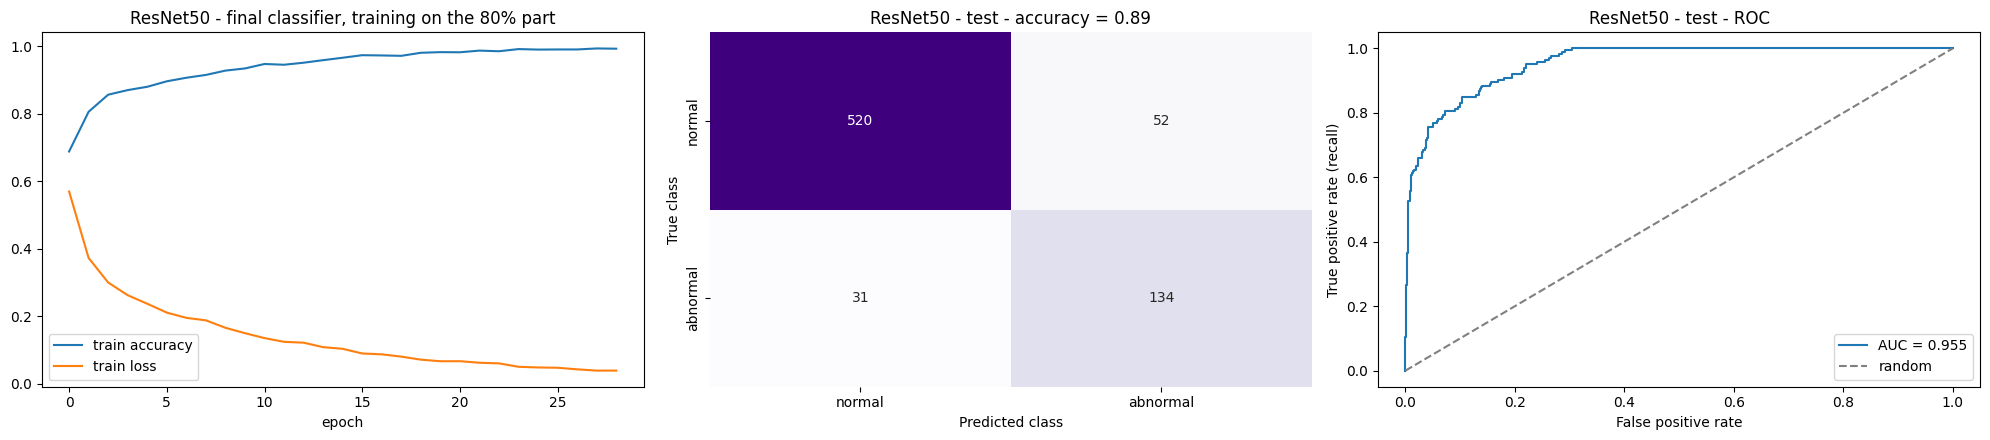

VGG16 : final classifier stopped after 49 epochs
==================== VGG16 - test set
              precision    recall  f1-score   support

      normal       0.93      0.89      0.91       572
    abnormal       0.67      0.76      0.72       165

    accuracy                           0.86       737
   macro avg       0.80      0.83      0.81       737
weighted avg       0.87      0.86      0.87       737



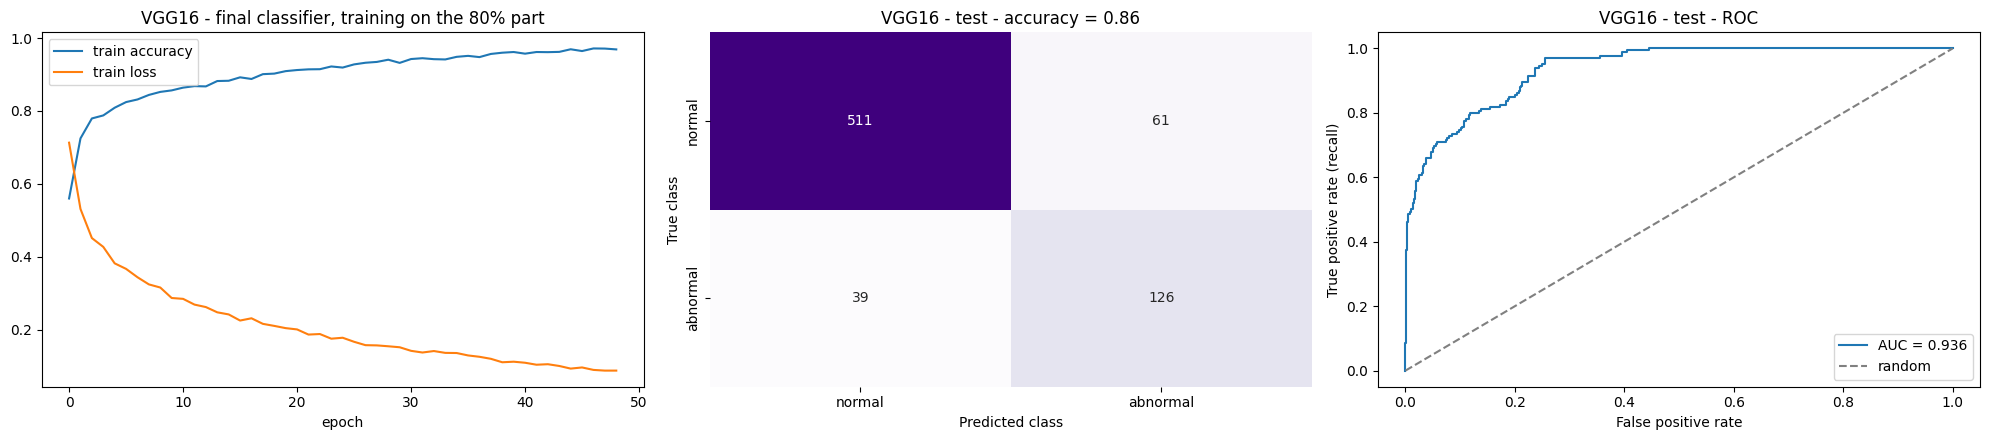

          accuracy  precision  recall     f1    auc
ResNet50     0.887      0.720   0.812  0.764  0.955
VGG16        0.864      0.674   0.764  0.716  0.936


In [13]:
# ==================== 6. TEST: the final classifier learns on the whole 80% part, then is tested ONCE on the 20% ====================
# the same method as the folds (early stopping on 10% of the train part): nothing is chosen with the test wavs
final_heads = {}
test_results = {}
for model_name_txt in all_model_name_txt:
    F_train = features[model_name_txt][~is_test]
    F_test = features[model_name_txt][is_test]
    head, final_history = train_head(F_train, y_train, np.arange(len(y_train)))
    print(model_name_txt, ": final classifier stopped after", len(final_history.history["loss"]), "epochs")
    final_heads[model_name_txt] = head

    y_test_prob = head.predict(F_test, verbose=0).ravel()
    y_test_pred = (y_test_prob > 0.5).astype(int)
    false_positive_rate, true_positive_rate, thresholds = roc_curve(y_test, y_test_prob)
    test_results[model_name_txt] = {
        "accuracy": accuracy_score(y_test, y_test_pred),
        "precision": precision_score(y_test, y_test_pred),
        "recall": recall_score(y_test, y_test_pred),
        "f1": f1_score(y_test, y_test_pred),
        "auc": auc(false_positive_rate, true_positive_rate),
    }
    report = classification_report(y_test, y_test_pred, target_names=["normal", "abnormal"])
    print("====================", model_name_txt, "- test set")
    print(report)
    with open(plots_folder + "tp8_" + model_name_txt + "_test_report.txt", "w") as f:
        f.write(model_name_txt + " (transfer learning) - test set (" + str(len(y_test)) + " wavs never seen)\n\n"
                + report)

    # ONE test figure: the training curve of the final classifier, the confusion matrix and the ROC curve (test)
    plt.figure(figsize=(20, 4.5))
    plt.subplot(1, 3, 1)
    plt.plot(final_history.history["accuracy"], label="train accuracy")
    plt.plot(final_history.history["loss"], label="train loss")
    plt.title(model_name_txt + " - final classifier, training on the 80% part")
    plt.xlabel("epoch")
    plt.legend()
    plt.subplot(1, 3, 2)
    PlotConfusionMatrix(confusion_matrix(y_test, y_test_pred),
                        model_name_txt + " - test - accuracy = {:.2f}".format(test_results[model_name_txt]["accuracy"]))
    plt.subplot(1, 3, 3)
    plot_roc(y_test, y_test_prob, model_name_txt + " - test - ROC")
    plt.tight_layout()
    plt.savefig(plots_folder + "tp8_" + model_name_txt + "_test.png")
    plt.show()

    # the probabilities of this model, for the ensemble (notebook 08): out-of-fold (validation) + test
    oof_prob, oof_fold = oof[model_name_txt]
    save_data({"model": model_name_txt, "train_names": list(files[~is_test]), "train_y": list(y_train),
               "fold": list(oof_fold), "oof_prob": list(oof_prob), "test_names": list(files[is_test]),
               "test_y": list(y_test), "test_prob": list(y_test_prob)},
              project_folder + "probs_" + model_name_txt.lower() + ".data")

print(pd.DataFrame(test_results).T.round(3))

In [14]:
# ==================== 7. MLflow (Service 6): one run per pre-trained model ====================
# the server and our experiment (the MLflow container must be running: docker compose up -d mlflow-server)
mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("audio_benchmark_final")    # the same experiment as the SVM, the tree and the CNN

for model_name_txt in all_model_name_txt:
    model_table = table[table["model"] == model_name_txt]    # the 3 folds of this model

    with mlflow.start_run(run_name=model_name_txt.lower()):    # "resnet50" or "vgg16"
        # 1. params = the settings we chose
        mlflow.log_param("model", model_name_txt)
        mlflow.log_param("features", "mel spectrogram 40 x 157 -> magma image 224 x 224 x 3")
        mlflow.log_param("transfer_learning", "feature extractor (ImageNet weights, frozen)")
        mlflow.log_param("classifier", "BatchNormalization + Dense 256 + Dropout 0.5 + Dense 1")
        mlflow.log_param("optimizer", "adam")
        mlflow.log_param("learning_rate", 0.0001)
        mlflow.log_param("epochs", "early stopping on 10% of the training wavs (patience 10, at most 60)")
        mlflow.log_param("merge", "Farah's classifier + Zaineb's early stopping and Dense 256")
        mlflow.log_param("batch_size", BATCH_SIZE)
        mlflow.log_param("class_weight", "balanced")
        mlflow.log_param("n_folds", 3)
        mlflow.log_param("protocol", "3 folds on the 80% train part (validation), final model on the 80%, tested on the 20%")
        mlflow.log_param("n_train", len(y_train))
        mlflow.log_param("n_test", len(y_test))

        # 2. metrics = validation (the mean of the 3 folds, the same names as the other runs) + test
        for metric in metrics:
            mlflow.log_metric("mean_" + metric, model_table[metric].mean())
            mlflow.log_metric("test_" + metric, test_results[model_name_txt][metric])
        for r in results:    # the results of each fold, also here: fold1_accuracy, fold1_precision, ..., fold3_auc
            if r["model"] == model_name_txt:
                for metric in metrics:
                    mlflow.log_metric("fold" + str(r["fold"]) + "_" + metric, r[metric])

        # 3. artifacts = the figures of this model: plots/validation/ and plots/test/
        for fold in [1, 2, 3]:
            mlflow.log_artifact(plots_folder + "tp8_" + model_name_txt + "_val_fold" + str(fold) + ".png",
                                artifact_path="plots/validation")
        mlflow.log_artifact(plots_folder + "tp8_" + model_name_txt + "_val_summary.png", artifact_path="plots/validation")
        mlflow.log_artifact(plots_folder + "tp8_" + model_name_txt + "_test.png", artifact_path="plots/test")
        mlflow.log_artifact(plots_folder + "tp8_" + model_name_txt + "_test_report.txt", artifact_path="plots/test")

        # 4. the model = the pre-trained part + the final classifier (trained on the 80% part, the tested one)
        # -> ONE model: image -> probability of "abnormal"
        # (its input = the image made by make_images() and then preprocess_input(), like in step 2)
        final_model = Sequential([Input(shape=(224, 224, 3)), base_models[model_name_txt], final_heads[model_name_txt]])
        mlflow.keras.log_model(final_model, "model")    # ~100 MB for ResNet50, ~60 MB for VGG16

        # 5. the 3 folds: 1 small run per fold INSIDE this run (nested=True), with its curves and its results
        for r in results:
            if r["model"] == model_name_txt:
                fold = r["fold"]
                h = all_histories[model_name_txt][fold - 1].history    # what Keras saved after each epoch
                with mlflow.start_run(run_name=model_name_txt.lower() + "_fold" + str(fold), nested=True):
                    mlflow.log_param("fold", fold)
                    # 1 point per epoch -> MLflow draws the curves (tab "Model metrics"): train vs the early-stopping
                    # part (10% of the training wavs of the fold); each fold stops at its own epoch
                    for epoch in range(len(h["loss"])):
                        mlflow.log_metric("train_loss", h["loss"][epoch], step=epoch + 1)
                        mlflow.log_metric("stop_loss", h["val_loss"][epoch], step=epoch + 1)
                        mlflow.log_metric("train_accuracy", h["accuracy"][epoch], step=epoch + 1)
                        mlflow.log_metric("stop_accuracy", h["val_accuracy"][epoch], step=epoch + 1)
                    # the results on the VALIDATION third of this fold
                    mlflow.log_metric("val_accuracy", r["accuracy"])
                    mlflow.log_metric("val_precision", r["precision"])
                    mlflow.log_metric("val_recall", r["recall"])
                    mlflow.log_metric("val_f1", r["f1"])
                    mlflow.log_metric("val_auc", r["auc"])
                    mlflow.log_artifact(plots_folder + "tp8_" + model_name_txt + "_val_fold" + str(fold) + ".png",
                                        artifact_path="plots/validation")
    print(model_name_txt, ": final model saved in MLflow")

2026/11/27 11:48:57 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.


2026/11/27 11:49:19 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


🏃 View run resnet50_fold1 at: http://localhost:5000/#/experiments/2/runs/acb2f0c2b2e24b7d862d128446e42888
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run resnet50_fold2 at: http://localhost:5000/#/experiments/2/runs/74abd1e9f4974d4aafb8ba3686f1681d
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run resnet50_fold3 at: http://localhost:5000/#/experiments/2/runs/d5b5cce165fb493d8492a2442c750a2b
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run resnet50 at: http://localhost:5000/#/experiments/2/runs/c4951b31b36c492ea483efcaa6afe0fe
🧪 View experiment at: http://localhost:5000/#/experiments/2


... (4 outputs left out)

🏃 View run vgg16_fold2 at: http://localhost:5000/#/experiments/2/runs/ebba4352731d432b88d41bd6161b4470
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run vgg16_fold3 at: http://localhost:5000/#/experiments/2/runs/fa2cb3c6ad764ae1913ea4141a55563e
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run vgg16 at: http://localhost:5000/#/experiments/2/runs/90e5d3a4e5264840b346b1f68cbd9ef5
🧪 View experiment at: http://localhost:5000/#/experiments/2


VGG16 : final model saved in MLflow


In [15]:
# All the final runs of the experiment (SVM, tree, CNN, ResNet50, VGG16, ...), the highest validation recall first:
# the project keeps the model with the highest recall of abnormal (the sick hearts)
runs = mlflow.search_runs(experiment_names=["audio_benchmark_final"])
runs = runs[runs["metrics.mean_recall"].notna() & runs["metrics.test_recall"].notna()]    # the final main runs only
if "tags.superseded" in runs.columns:
    runs = runs[runs["tags.superseded"].isna()]    # an older version of a notebook (kept in MLflow as history)
columns = ["tags.mlflow.runName", "params.model", "metrics.mean_recall", "metrics.mean_f1",
           "metrics.test_recall", "metrics.test_f1", "metrics.test_auc"]
runs[columns].sort_values("metrics.mean_recall", ascending=False).round(3)

,tags.mlflow.runName,params.model,metrics.mean_recall,metrics.mean_f1,metrics.test_recall,metrics.test_f1,metrics.test_auc
47,cnn,CNN,0.938,0.628,0.909,0.661,0.932
12,svm_rbf_extended72,SVM,0.894,0.705,0.915,0.728,0.944
0,ensemble,Ensemble,0.858,0.714,0.933,0.726,0.954
48,decision_tree_entropy_depth7,DecisionTree,0.820,0.657,0.927,0.643,0.891
33,transformer_cnn,TransformerCNN,0.815,0.658,0.861,0.684,0.933
8,resnet50,ResNet50,0.793,0.746,0.812,0.764,0.955
4,vgg16,VGG16,0.784,0.721,0.764,0.716,0.936
